In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pyLBA import LBAModel, LBAParameters

In [2]:
# Create model and parameters
model = LBAModel()

original_params = LBAParameters(
    A=4,
    b=[6, 10, 20],
    v=1,
    s=1,
    tau=0
)

print(f"Model: {model.name}")
print(f"Parameters: {original_params}")

Model: Linear Ballistic Accumulator
Parameters: LBAParameters(A=4.0, b=array([ 6., 10., 20.]), v=1.0, s=1.0, tau=0.0)


In [3]:
from pyLBA.synthetic import generate_LBA

In [4]:
# Generate synthetic data
data = generate_LBA(n_trials=200,
                    parameters=original_params,
                    n_acc=3,
                    seed=42) # For reproducibility
# Display first few rows
print(f"\n   First few rows of generated data:")
print(data.head())


   First few rows of generated data:
         rt  response
0  2.521009         0
1  2.307963         0
2  1.070721         0
3  1.863868         0
4  1.961397         0


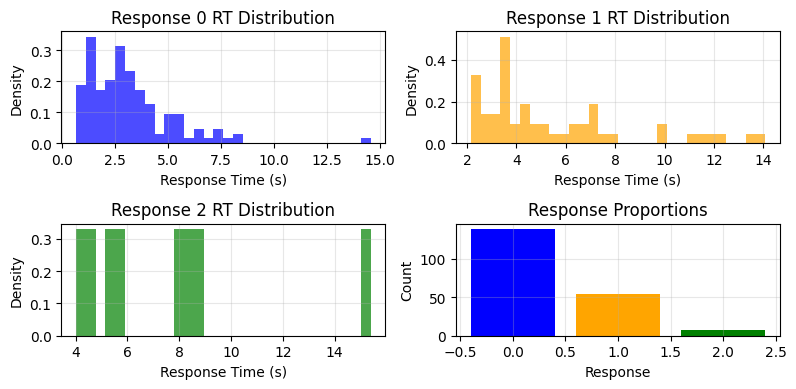

In [5]:
# Create visualizations
fig, axes = plt.subplots(2, 2, figsize=(8, 4))

# RT histograms by response
responses = sorted(data['response'].unique())
colors = ['blue', 'orange', 'green']

for i, response in enumerate(responses):
    if i < 3:  # Only plot first 3 responses
        row = i // 2
        col = i % 2
        ax = axes[row, col]
        
        subset = data[data['response'] == response]
        ax.hist(subset['rt'], bins=30, alpha=0.7, color=colors[i], density=True)
        ax.set_title(f'Response {response} RT Distribution')
        ax.set_xlabel('Response Time (s)')
        ax.set_ylabel('Density')
        ax.grid(True, alpha=0.3)

# Response proportions
response_counts = data['response'].value_counts().sort_index()
axes[1, 1].bar(response_counts.index, response_counts.values, color=colors[:len(response_counts)])
axes[1, 1].set_title('Response Proportions')
axes[1, 1].set_xlabel('Response')
axes[1, 1].set_ylabel('Count')
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [6]:
import pymc as pm
import arviz as az

In [7]:
custom_priors = {
    'A': 4,
    'v': 1,
    's': 1,
    'tau': 0
}


fitted_model = model.fit_mcmc(
    data=data,
    priors=custom_priors,
    draws=200,      # Reduced for faster demo
    tune=200,       # Reduced for faster demo
    chains=2,       # Reduced for faster demo
    cores=2,
    random_seed=42,
    progressbar=False
)

Initializing NUTS using jitter+adapt_diag...


/home/dev/pyLBA/.venv/lib/python3.10/site-packages/pytensor/link/c/cmodule.py:2968: UserWarning: PyTensor could not link to a BLAS installation. Operations that might benefit from BLAS will be severely degraded.
This usually happens when PyTensor is installed via pip. We recommend it be installed via conda/mamba/pixi instead.
Alternatively, you can use an experimental backend such as Numba or JAX that perform their own BLAS optimizations, by setting `pytensor.config.mode == 'NUMBA'` or passing `mode='NUMBA'` when compiling a PyTensor function.
For more options and details see https://pytensor.readthedocs.io/en/latest/troubleshooting.html#how-do-i-configure-test-my-blas-library
  warnings.warn(


Multiprocess sampling (2 chains in 2 jobs)


NUTS: [b_gap]


Sampling 2 chains for 200 tune and 200 draw iterations (400 + 400 draws total) took 0 seconds.


We recommend running at least 4 chains for robust computation of convergence diagnostics


The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


In [8]:
print(az.summary(fitted_model.trace, var_names=["b"]))
predictions = fitted_model.predict(100, seed=42)
predictions.head()

        mean     sd  hdi_3%  hdi_97%  mcse_mean  mcse_sd  ess_bulk  ess_tail  \
b[0]   5.936  0.149   5.645    6.198      0.008    0.006     328.0     248.0   
b[1]   9.835  0.381   9.195   10.607      0.023    0.024     295.0     117.0   
b[2]  14.579  0.823  13.130   16.128      0.038    0.040     450.0     334.0   

      r_hat  
b[0]   1.00  
b[1]   1.02  
b[2]   1.00  


,rt,response
0,1.500443,0
1,2.829962,1
2,1.956801,0
3,2.556414,0
4,1.764732,1
